In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/rajmukhiya/iris-species-dataset/iris.csv


In [2]:

import pandas as pd

df = pd.read_csv(
    "/kaggle/input/datasets/rajmukhiya/iris-species-dataset/iris.csv"
)

print(df.head())


   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


In [3]:

print("Rows aur Columns:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFlower Species:")
print(df.iloc[:, -1].value_counts())


Rows aur Columns: (150, 5)

Column Names:
Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='object')

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Flower Species:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [4]:

# Input features
X = df[[
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]]

# Target variable
y = df["species"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFirst 5 features:")
print(X.head())

print("\nFirst 5 targets:")
print(y.head())


X shape: (150, 4)
y shape: (150,)

First 5 features:
   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2

First 5 targets:
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object


In [5]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 120
Testing samples: 30


In [6]:

from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [7]:

from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100, "%")


Accuracy: 0.9
Accuracy percentage: 90.0 %


Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  2  8]]


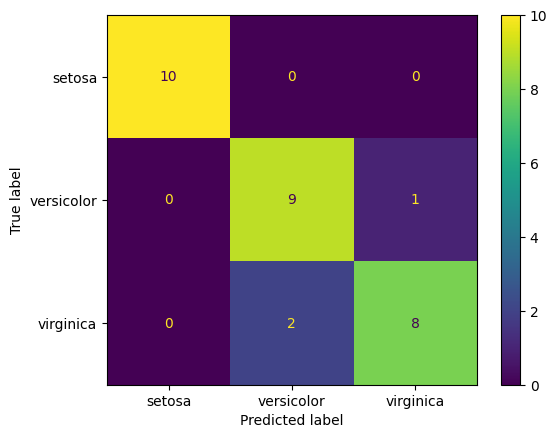

In [8]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot()
plt.show()


In [9]:

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



In [10]:

new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=[
        "sepal_length",
        "sepal_width",
        "petal_length",
        "petal_width"
    ]
)

prediction = model.predict(new_flower)

print("Predicted species:", prediction[0])


Predicted species: setosa


In [11]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

for trees in [10, 50, 100, 200]:
    model_test = RandomForestClassifier(
        n_estimators=trees,
        random_state=42
    )

    model_test.fit(X_train, y_train)

    predictions = model_test.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    print(f"Trees: {trees}, Accuracy: {accuracy:.2%}")


Trees: 10, Accuracy: 96.67%
Trees: 50, Accuracy: 90.00%
Trees: 100, Accuracy: 90.00%
Trees: 200, Accuracy: 90.00%


In [12]:

import pandas as pd

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model_test.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)


        Feature  Importance
2  petal_length    0.453793
3   petal_width    0.412449
0  sepal_length    0.115873
1   sepal_width    0.017885


In [13]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [10, 50, 100, 200],
    "max_depth": [None, 2, 3, 5],
    "min_samples_split": [2, 5]
}

rf = RandomForestClassifier(random_state=42)

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(grid_search.best_score_)

print("\nTest Accuracy:")
print(grid_search.best_estimator_.score(X_test, y_test))


Best Parameters:
{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 10}

Best Cross-Validation Accuracy:
0.9583333333333334

Test Accuracy:
0.9666666666666667


In [14]:

import joblib

best_model = grid_search.best_estimator_

joblib.dump(best_model, "iris_random_forest.pkl")

print("Model saved successfully!")


Model saved successfully!


In [16]:

loaded_model = joblib.load("iris_random_forest.pkl")

print("Model loaded successfully!")


Model loaded successfully!


In [17]:

import pandas as pd

new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=[
        "sepal_length",
        "sepal_width",
        "petal_length",
        "petal_width"
    ]
)

prediction = loaded_model.predict(new_flower)

print("Predicted flower:", prediction[0])


Predicted flower: setosa
